# Q2 – Notebook 3 of 3: RoBERTa Fine-Tuning, Ablation, Evaluation and Comparison
**DSL 504 – NLP Group Assignment 2 · Question 2**

This notebook fine-tunes `roberta-base` end to end with **masked mean pooling** over the last hidden layer, runs the **ablation** (mean pooling vs first-token pooling), evaluates on the test set (once per model) and compares RoBERTa with the BiGRU baseline from notebook 2: accuracy, macro-F1, per-class F1, MAE, normalised confusion matrices (adjacent vs distant errors), qualitative examples, and token-level importance.

**Needs:** the outputs of notebook 1 (`prep/`) and notebook 2 (baseline histories and test predictions on Drive).

**About the training cells:** section 3a runs a *live* short fine-tuning (150 steps) so that the training loop and its output are visible in this notebook (a demonstration, nothing is saved). Section 3b trains the real runs; a run is **skipped if its checkpoint and history file already exist**, and section 3c prints the full per-epoch training log of every run from the saved histories. Training all three runs from scratch takes about 3 hours on a free Colab GPU.

In [1]:
!pip -q install -U transformers accelerate scikit-learn seaborn > /dev/null 2>&1

import os
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
import re, random, time, json, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt, seaborn as sns
import transformers
from transformers import AutoTokenizer, AutoModel, RobertaTokenizerFast, DataCollatorWithPadding, get_linear_schedule_with_warmup
transformers.logging.set_verbosity_error()
try: transformers.logging.disable_progress_bar()
except Exception: pass

try:
    from google.colab import drive
    drive.mount('/content/drive')
    CKPT_DIR = '/content/drive/MyDrive/GROUP_ASSIGNMENT_2/Q2_final'
except ImportError:
    CKPT_DIR = './Q2_final'
PREP_DIR = f'{CKPT_DIR}/prep'            # artifacts written by notebook 1
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(PREP_DIR, exist_ok=True)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device, '| torch', torch.__version__, '| transformers', transformers.__version__)
assert device.type == 'cuda', 'Select a GPU runtime: Runtime > Change runtime type > GPU'
assert os.path.exists(f'{PREP_DIR}/classic.npz'), 'Run notebook 1 (preprocessing) first.'

Mounted at /content/drive
device: cuda | torch 2.11.0+cu130 | transformers 5.21.0


## 0. Configuration
`FORCE_RETRAIN = False` reuses finished runs; `RUN_DEMO = True` runs the short live demonstration (about 2 minutes).

In [2]:
FORCE_RETRAIN = False
RUN_DEMO, DEMO_STEPS = True, 150
SEEDS = [42, 43]
RUNS = [('mean', 42), ('mean', 43), ('first', 42)]          # (pooling, seed); 'first' is the ablation run
MODEL_NAME, MAX_LEN_RB = 'roberta-base', 256
RB_BS, RB_LR, RB_WD, RB_WARMUP, RB_EPOCHS, EVALS_PER_EPOCH, CLIP = 32, 2e-5, 0.01, 0.06, 2, 2, 1.0
TOL = 0.003                  # allowed gap between logged and re-computed validation macro-F1
UNK = 1
COLS = ['epoch', 'train_loss', 'train_f1', 'val_loss', 'val_acc', 'val_f1']

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
def ckpt_path(kind, s): return f'{CKPT_DIR}/roberta_{kind}_seed{s}.pt'
def hist_path(kind, s): return f'{CKPT_DIR}/roberta_{kind}_seed{s}_history.json'
def todo(kind, s): return FORCE_RETRAIN or not (os.path.exists(ckpt_path(kind, s)) and os.path.exists(hist_path(kind, s)))
print({f'{k}_s{s}': ('train' if todo(k, s) else 'reuse') for k, s in RUNS})

{'mean_s42': 'reuse', 'mean_s43': 'reuse', 'first_s42': 'reuse'}


## 1. Load the preprocessed data and the baseline results
RoBERTa inputs come from notebook 1 (`RobertaTokenizerFast`, `<s>`/`</s>`, truncation to 256, **dynamic padding** with `DataCollatorWithPadding`). The baseline histories, parameter count and test predictions come from notebook 2.

In [3]:
Z = np.load(f'{PREP_DIR}/classic.npz')
ytr, yva, yte, Xte, te_len = Z['ytr'], Z['yva'], Z['yte'], Z['Xte'], Z['te_len']          # Xte/te_len only for the OOV and length tags
R_ = np.load(f'{PREP_DIR}/roberta_ids.npz')
def unpack(name): return np.split(R_[f'{name}_flat'], np.cumsum(R_[f'{name}_lens'])[:-1])
tok_rb = RobertaTokenizerFast.from_pretrained(MODEL_NAME)
print('tokenizer class:', type(tok_rb).__name__)
collator = DataCollatorWithPadding(tok_rb)                   # dynamic padding

class RBData(Dataset):
    def __init__(self, ids, labels): self.ids, self.labels = ids, labels
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        x = self.ids[i].tolist()
        return {'input_ids': x, 'attention_mask': [1] * len(x), 'labels': int(self.labels[i])}

rb_val, rb_test = RBData(unpack('val'), yva), RBData(unpack('test'), yte)
need_train_data = RUN_DEMO or any(todo(k, s) for k, s in RUNS)
if need_train_data: rb_train = RBData(unpack('train'), ytr)
test_df = pd.DataFrame({'text': json.load(open(f'{PREP_DIR}/test_texts.json')), 'label': yte})
print(f'val {len(rb_val)} | test {len(rb_test)} | train {len(rb_train) if need_train_data else "not loaded (no training needed)"}')
print('example tokens:', tok_rb.convert_ids_to_tokens(rb_test.ids[0][:12].tolist()))

# baseline results from notebook 2
BASE_INFO = json.load(open(f'{CKPT_DIR}/baseline_info.json')); P_BASE = BASE_INFO['params_M']
HIST, MINS = {}, {}
for s in SEEDS:
    d = json.load(open(f'{CKPT_DIR}/baseline_seed{s}_history.json'))
    HIST[('baseline', s)] = pd.DataFrame(d['rows'], columns=COLS); MINS[('baseline', s)] = d['minutes']
    assert os.path.exists(f'{CKPT_DIR}/final_testpred_baseline_s{s}.npy'), 'Run notebook 2 first (baseline test predictions missing).'
print(f'baseline: {P_BASE:.2f}M parameters, histories and test predictions loaded')

tokenizer class: RobertaTokenizer
val 5000 | test 5000 | train 200000
example tokens: ['<s>', 'These', 'Ġare', 'ĠAW', 'FUL', '.', 'ĠThey', 'Ġare', 'Ġsee', 'Ġthrough', ',', 'Ġthe']
baseline: 8.03M parameters, histories and test predictions loaded


## 2. Model: RoBERTa with masked mean pooling
`roberta-base` (12 layers, 768-d) → **masked mean** of the last hidden layer over the non-padded tokens → dropout 0.1 → `Linear(768 → 5)`. All weights are fine-tuned end to end. With `pooling='first'` the `<s>` representation is used instead (ablation).

In [4]:
class RobertaCls(nn.Module):
    def __init__(self, name=MODEL_NAME, n_cls=5, dropout=0.1, pooling='mean', attn_impl=None):
        super().__init__()
        kw = dict(add_pooling_layer=False)
        if attn_impl: kw['attn_implementation'] = attn_impl
        self.enc = AutoModel.from_pretrained(name, **kw)
        self.pooling = pooling
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(self.enc.config.hidden_size, n_cls)
    def pool(self, h, mask):
        h = h.float()
        if self.pooling == 'mean':                                # masked mean over non-padded tokens
            m = mask.unsqueeze(-1).float()
            return (h * m).sum(1) / m.sum(1).clamp(min=1e-9)
        return h[:, 0]                                            # <s> token
    def forward(self, input_ids=None, attention_mask=None, inputs_embeds=None, output_attentions=False):
        out = self.enc(input_ids=input_ids, inputs_embeds=inputs_embeds,
                       attention_mask=attention_mask, output_attentions=output_attentions)
        logits = self.fc(self.drop(self.pool(out.last_hidden_state, attention_mask)))
        return (logits, out.attentions) if output_attentions else logits

@torch.no_grad()
def rb_logits(model, dataset, bs=64):                             # batches are length-sorted to minimise padding
    model.eval()
    order = np.argsort([len(x) for x in dataset.ids]); out = torch.zeros(len(dataset), 5)
    for i in range(0, len(order), bs):
        idx = order[i:i + bs]; b = collator([dataset[j] for j in idx])
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            lg = model(b['input_ids'].to(device), b['attention_mask'].to(device))
        out[torch.as_tensor(idx)] = lg.float().cpu()
    return out

def scores(lg, y):
    p = lg.argmax(1).numpy()
    return F.cross_entropy(lg, torch.as_tensor(y)).item(), accuracy_score(y, p), f1_score(y, p, average='macro')

def load_rb(path, pooling):
    m = RobertaCls(pooling=pooling).to(device); m.load_state_dict(torch.load(path, map_location=device)); return m.eval()

## 3. Training procedure
Cross-entropy loss; **AdamW** (lr 2e-5, weight decay 0.01, not applied to bias and LayerNorm weights); **6% linear warm-up followed by linear decay**; **fp16 mixed precision** (`GradScaler`); gradient clipping (max-norm 1.0); batch size 32 (so gradient accumulation was not needed); 2 epochs with validation every half epoch; the checkpoint with the best **validation** macro-F1 is kept. Data are served with a PyTorch `DataLoader` and a dynamic-padding collator. Training metrics are running averages over the preceding half epoch (dropout active).

In [5]:
def train_roberta(pooling, seed, max_steps=None, save=True):
    set_seed(seed); t0 = time.time()
    model = RobertaCls(pooling=pooling).to(device)
    nd = ['bias', 'LayerNorm.weight']
    groups = [{'params': [p for n, p in model.named_parameters() if not any(k in n for k in nd)], 'weight_decay': RB_WD},
              {'params': [p for n, p in model.named_parameters() if any(k in n for k in nd)], 'weight_decay': 0.0}]
    opt = torch.optim.AdamW(groups, lr=RB_LR)
    g = torch.Generator(); g.manual_seed(seed)
    loader = DataLoader(rb_train, batch_size=RB_BS, shuffle=True, collate_fn=collator, generator=g, num_workers=2)
    total = max_steps if max_steps else len(loader) * RB_EPOCHS            # max_steps is only used for the short live demo
    every = max_steps if max_steps else len(loader) // EVALS_PER_EPOCH
    sched = get_linear_schedule_with_warmup(opt, int(RB_WARMUP * total), total)
    scaler = torch.amp.GradScaler('cuda')
    hist, best, step, tl, n, P, Y = [], -1, 0, 0.0, 0, [], []
    for ep in range(RB_EPOCHS):
        for b in loader:
            model.train()
            ids, am, y = b['input_ids'].to(device), b['attention_mask'].to(device), b['labels'].to(device)
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                logits = model(ids, am)
            loss = F.cross_entropy(logits.float(), y)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), CLIP); scaler.step(opt); scaler.update(); sched.step()
            step += 1; tl += loss.item() * len(y); n += len(y); P.append(logits.argmax(1).cpu()); Y.append(y.cpu())
            if step % every == 0 or step == total:
                vl, va, vf = scores(rb_logits(model, rb_val), yva)
                trf1 = f1_score(torch.cat(Y).numpy(), torch.cat(P).numpy(), average='macro')
                hist.append([round(step / len(loader), 2), tl / n, trf1, vl, va, vf]); tl, n, P, Y = 0.0, 0, [], []
                print(f'roberta-{pooling} s{seed} epoch {step/len(loader):.2f}: train loss {hist[-1][1]:.4f} F1 {trf1:.4f} | val loss {vl:.4f} acc {va:.4f} F1 {vf:.4f}')
                if vf > best:
                    best = vf
                    if save: torch.save(model.state_dict(), ckpt_path(pooling, seed))
            if step >= total: break
        if step >= total: break
    if save: json.dump(dict(rows=hist, minutes=(time.time() - t0) / 60), open(hist_path(pooling, seed), 'w'))
    del model, opt; torch.cuda.empty_cache()
    return hist

### 3a. Live demonstration: the first 150 training steps (nothing is saved, seed 0)
This shows the fine-tuning loop running, with one validation pass at the end. It is **not** one of the reported runs (the learning-rate schedule is compressed to 150 steps, so its numbers are not comparable with the real runs).

In [6]:
if RUN_DEMO:
    print(f'--- live demo run: {DEMO_STEPS} steps, not saved, not used for any result ---')
    _ = train_roberta('mean', 0, max_steps=DEMO_STEPS, save=False)
else:
    print('RUN_DEMO = False: demonstration skipped')

--- live demo run: 150 steps, not saved, not used for any result ---
roberta-mean s0 epoch 0.02: train loss 1.2063 F1 0.4514 | val loss 1.0432 acc 0.5486 F1 0.5293


### 3b. Training of the reported runs
RoBERTa mean pooling (seeds 42 and 43) and the ablation run with first-token pooling (seed 42). A run is trained only if its checkpoint or history file is missing (or `FORCE_RETRAIN = True`).

In [7]:
for kind, s in RUNS:
    if todo(kind, s):
        print(f'\n=== training roberta-{kind} seed {s} ===')
        train_roberta(kind, s)
    else:
        print(f'roberta-{kind:5s} seed {s}: checkpoint and history found -> training skipped (its log is printed in 3c)')

roberta-mean  seed 42: checkpoint and history found -> training skipped (its log is printed in 3c)
roberta-mean  seed 43: checkpoint and history found -> training skipped (its log is printed in 3c)
roberta-first seed 42: checkpoint and history found -> training skipped (its log is printed in 3c)


### 3c. Training log of the reported runs
The per-evaluation values saved during training of each run (same format as the live training output), the best evaluation point and the training time.

In [8]:
for kind, s in RUNS:
    d = json.load(open(hist_path(kind, s)))
    HIST[(kind, s)] = pd.DataFrame(d['rows'], columns=COLS); MINS[(kind, s)] = d['minutes']
def best_row(h): return h.loc[h.val_f1.idxmax()]

for kind, s in RUNS:
    h = HIST[(kind, s)]
    print(f'--- roberta-{kind} seed {s}: saved training log ({MINS[(kind, s)]:.1f} min) ---')
    for r in h.itertuples():
        print(f'roberta-{kind} s{s} epoch {r.epoch:.2f}: train loss {r.train_loss:.4f} F1 {r.train_f1:.4f} | val loss {r.val_loss:.4f} acc {r.val_acc:.4f} F1 {r.val_f1:.4f}')
    b = best_row(h); print(f'-> best validation macro-F1 {b.val_f1:.4f} at epoch {b.epoch:.2f}\n')

--- roberta-mean seed 42: saved training log (54.7 min) ---
roberta-mean s42 epoch 0.50: train loss 1.0047 F1 0.5505 | val loss 0.9594 acc 0.5986 F1 0.5920
roberta-mean s42 epoch 1.00: train loss 0.9124 F1 0.5957 | val loss 0.9044 acc 0.6102 F1 0.6065
roberta-mean s42 epoch 1.50: train loss 0.8451 F1 0.6270 | val loss 0.9066 acc 0.6054 F1 0.6028
roberta-mean s42 epoch 2.00: train loss 0.8319 F1 0.6332 | val loss 0.9017 acc 0.6150 F1 0.6116
-> best validation macro-F1 0.6116 at epoch 2.00

--- roberta-mean seed 43: saved training log (53.8 min) ---
roberta-mean s43 epoch 0.50: train loss 1.0018 F1 0.5533 | val loss 0.9528 acc 0.5856 F1 0.5879
roberta-mean s43 epoch 1.00: train loss 0.9109 F1 0.5974 | val loss 0.9149 acc 0.6048 F1 0.6013
roberta-mean s43 epoch 1.50: train loss 0.8434 F1 0.6291 | val loss 0.9118 acc 0.6094 F1 0.6047
roberta-mean s43 epoch 2.00: train loss 0.8304 F1 0.6335 | val loss 0.9065 acc 0.6084 F1 0.6052
-> best validation macro-F1 0.6052 at epoch 2.00

--- roberta-

## 4. Checkpoint verification (validation set only)
Every saved best checkpoint is re-scored on the **validation** set and compared with the best validation macro-F1 logged during training, confirming that the checkpoints used for testing are the ones described by the logs. The test set is not touched here. The parameter count is measured as well.

In [9]:
P_RB = None
for kind, s in RUNS:
    model = load_rb(ckpt_path(kind, s), kind)
    P_RB = sum(p.numel() for p in model.parameters()) / 1e6
    _, acc, f1 = scores(rb_logits(model, rb_val), yva); logged = best_row(HIST[(kind, s)]).val_f1
    ok = abs(f1 - logged) <= TOL
    print(f'roberta-{kind:5s} seed {s}: recomputed val F1 {f1:.4f} vs logged {logged:.4f} -> {"MATCH" if ok else "MISMATCH"}')
    assert ok, 'checkpoint does not match its training log: do not run the test evaluation'
    del model; torch.cuda.empty_cache()
print(f'\nAll RoBERTa checkpoints verified. Parameters: BiGRU {P_BASE:.2f}M | RoBERTa {P_RB:.1f}M')

roberta-mean  seed 42: recomputed val F1 0.6116 vs logged 0.6116 -> MATCH
roberta-mean  seed 43: recomputed val F1 0.6052 vs logged 0.6052 -> MATCH
roberta-first seed 42: recomputed val F1 0.6096 vs logged 0.6096 -> MATCH

All RoBERTa checkpoints verified. Parameters: BiGRU 8.03M | RoBERTa 124.1M


## 5. Training / validation curves of both models
Loss and macro-F1 per epoch (BiGRU) and per half epoch (RoBERTa). Solid lines: seed 42; dashed: seed 43.

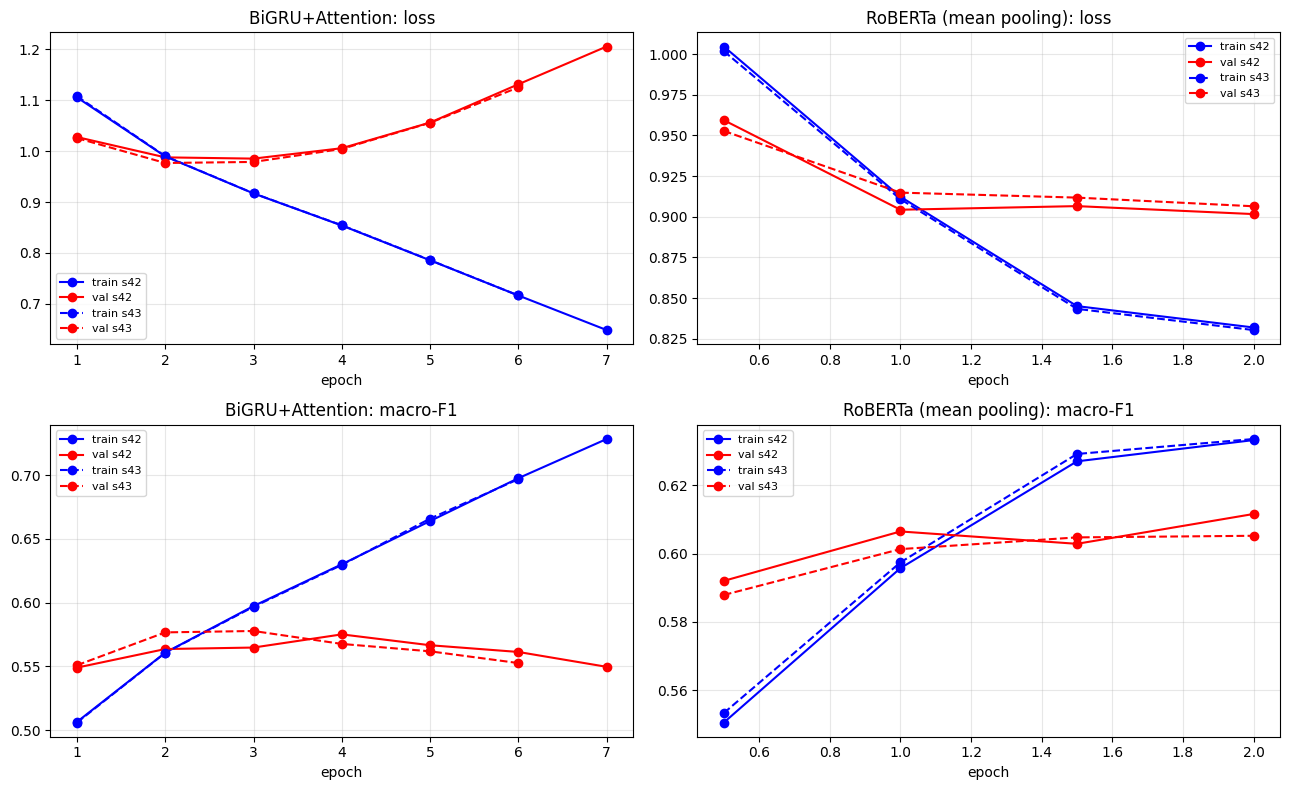

In [10]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
for s in SEEDS:
    ls = '-' if s == SEEDS[0] else '--'
    for col, key in ((0, ('baseline', s)), (1, ('mean', s))):
        h = HIST[key]
        ax[0, col].plot(h.epoch, h.train_loss, 'b' + ls, marker='o', label=f'train s{s}'); ax[0, col].plot(h.epoch, h.val_loss, 'r' + ls, marker='o', label=f'val s{s}')
        ax[1, col].plot(h.epoch, h.train_f1, 'b' + ls, marker='o', label=f'train s{s}');   ax[1, col].plot(h.epoch, h.val_f1, 'r' + ls, marker='o', label=f'val s{s}')
for a, t in zip(ax.flat, ['BiGRU+Attention: loss', 'RoBERTa (mean pooling): loss', 'BiGRU+Attention: macro-F1', 'RoBERTa (mean pooling): macro-F1']):
    a.set_title(t); a.set_xlabel('epoch'); a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{CKPT_DIR}/training_curves.png', dpi=150); plt.show()

## 6. Final evaluation on the TEST set (once per model)
Each model/seed is scored once; the predictions are cached on Drive and reused. The baseline predictions come from notebook 2. Metrics: accuracy, macro-F1, per-class F1, MAE, and the share of adjacent (off by 1 star) and distant (off by 2+ stars) errors; mean ± std (ddof=1) over the 2 seeds. Nothing is tuned or selected on the test set.

In [11]:
B, R = 'BiGRU+Attn', 'RoBERTa (mean)'

def get_test_preds_rb(s):
    path = ckpt_path('mean', s)
    cache = f'{CKPT_DIR}/testpred_mean_s{s}_{int(os.path.getmtime(path))}.npy'
    if os.path.exists(cache): p = np.load(cache)                      # evaluated before -> reuse
    else:
        model = load_rb(path, 'mean'); p = rb_logits(model, rb_test).argmax(1).numpy(); np.save(cache, p); del model; torch.cuda.empty_cache()
    np.save(f'{CKPT_DIR}/final_testpred_roberta_mean_s{s}.npy', p)
    return p

def compute_metrics(y, p):
    d = np.abs(y - p)
    out = dict(accuracy=accuracy_score(y, p), macro_F1=f1_score(y, p, average='macro'), MAE=d.mean(),
               adjacent_err=(d == 1).mean(), distant_err=(d >= 2).mean())
    for k, v in enumerate(f1_score(y, p, average=None, labels=range(5))): out[f'F1_{k+1}star'] = v
    return out

test_preds = {B: {s: np.load(f'{CKPT_DIR}/final_testpred_baseline_s{s}.npy') for s in SEEDS},
              R: {s: get_test_preds_rb(s) for s in SEEDS}}
rows = {n: pd.DataFrame([compute_metrics(yte, d[s]) for s in SEEDS]) for n, d in test_preds.items()}
fmt = lambda df: df.agg(['mean', 'std']).apply(lambda c: f'{c["mean"]:.4f} ± {c["std"]:.4f}')
summary = pd.DataFrame({k: fmt(v) for k, v in rows.items()})
display(summary); summary.to_csv(f'{CKPT_DIR}/test_summary.csv')
print('parameters: BiGRU %.2fM | RoBERTa %.1fM' % (P_BASE, P_RB))
print('training time per run: BiGRU %.1f min | RoBERTa %.1f min' % (np.mean([MINS[('baseline', s)] for s in SEEDS]), np.mean([MINS[('mean', s)] for s in SEEDS])))

,BiGRU+Attn,RoBERTa (mean)
accuracy,0.5754 ± 0.0059,0.6139 ± 0.0041
macro_F1,0.5712 ± 0.0048,0.6112 ± 0.0042
MAE,0.5129 ± 0.0052,0.4385 ± 0.0038
adjacent_err,0.3554 ± 0.0076,0.3412 ± 0.0040
distant_err,0.0692 ± 0.0017,0.0449 ± 0.0001
F1_1star,0.6671 ± 0.0029,0.7074 ± 0.0024
F1_2star,0.4741 ± 0.0130,0.5134 ± 0.0006
F1_3star,0.4220 ± 0.0169,0.4908 ± 0.0122
F1_4star,0.5509 ± 0.0046,0.5681 ± 0.0054
F1_5star,0.7418 ± 0.0217,0.7764 ± 0.0003


parameters: BiGRU 8.03M | RoBERTa 124.1M
training time per run: BiGRU 9.7 min | RoBERTa 54.3 min


## 7. Confusion matrices: adjacent vs distant errors
Row-normalised confusion matrices averaged over the 2 seeds. For ordinal ratings the *location* of an error matters: confusing 4★ with 5★ is much less harmful than confusing 1★ with 5★. MAE and the adjacent/distant split capture this; accuracy does not.

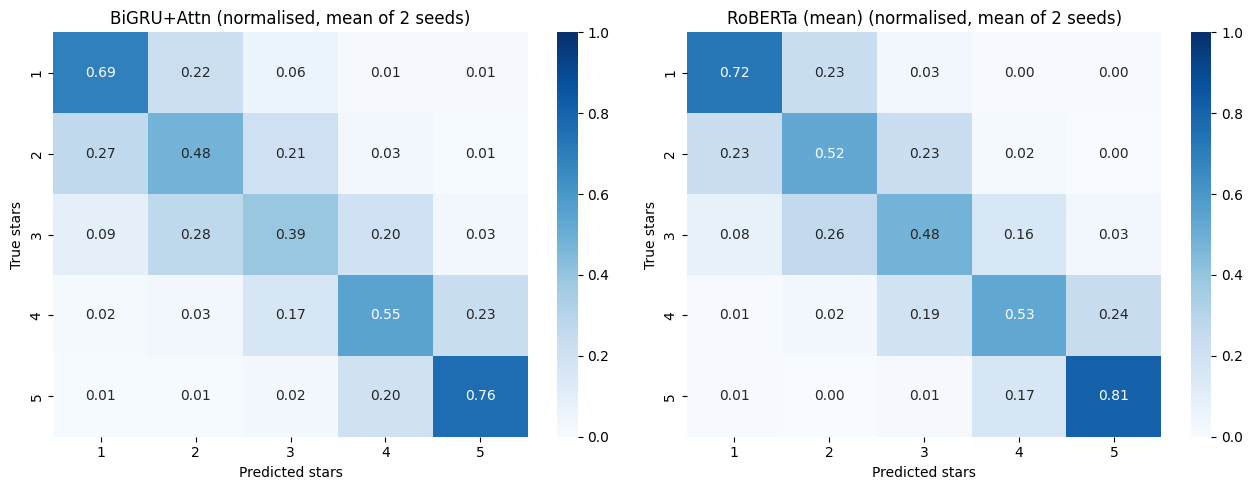

BiGRU+Attn: of all errors -> adjacent 83.7%, distant (>=2 stars) 16.3%
RoBERTa (mean): of all errors -> adjacent 88.4%, distant (>=2 stars) 11.6%
BiGRU+Attn | 4->5: 0.234 | 5->4: 0.198 | 1->5: 0.014 | 5->1: 0.009
RoBERTa (mean) | 4->5: 0.242 | 5->4: 0.166 | 1->5: 0.005 | 5->1: 0.005


In [12]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5)); CM = {}
for a, (name, d) in zip(axs, test_preds.items()):
    CM[name] = np.mean([confusion_matrix(yte, d[s], normalize='true') for s in SEEDS], axis=0)
    sns.heatmap(CM[name], annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=a, xticklabels=range(1, 6), yticklabels=range(1, 6))
    a.set_title(f'{name} (normalised, mean of {len(SEEDS)} seeds)'); a.set_xlabel('Predicted stars'); a.set_ylabel('True stars')
plt.tight_layout(); plt.savefig(f'{CKPT_DIR}/confusion_matrices.png', dpi=150); plt.show()

ERR_SHARE = {}
for name, d in test_preds.items():
    adj, dist = [], []
    for s in SEEDS:
        diff = np.abs(yte - d[s]); err = diff > 0
        adj.append((diff[err] == 1).mean()); dist.append((diff[err] >= 2).mean())
    ERR_SHARE[name] = (np.mean(adj), np.mean(dist))
    print(f'{name}: of all errors -> adjacent {np.mean(adj):.1%}, distant (>=2 stars) {np.mean(dist):.1%}')
for name, cm in CM.items():
    print(f'{name} | 4->5: {cm[3,4]:.3f} | 5->4: {cm[4,3]:.3f} | 1->5: {cm[0,4]:.3f} | 5->1: {cm[4,0]:.3f}')

## 8. Qualitative analysis
Seed-42 models. Reviews RoBERTa gets right but the BiGRU gets wrong (8 shown) and the opposite (4 shown). Likely causes are tagged with simple rules computed on the text: negation words, contrast connectives (*but/however*), very long or very short reviews, and out-of-vocabulary words (a proxy for misspellings and rare words). The direction of the errors is also computed. Sarcasm and mixed sentiment cannot be tagged automatically and are judged by reading the examples.

In [13]:
s0 = SEEDS[0]
q = test_df.copy().reset_index(drop=True)
q['base'], q['rob'], q['ntok'] = test_preds[B][s0], test_preds[R][s0], np.array(te_len)
rob_wins  = q[(q.base != q.label) & (q.rob == q.label)]
base_wins = q[(q.base == q.label) & (q.rob != q.label)]
print(f'RoBERTa right / BiGRU wrong: {len(rob_wins)} | BiGRU right / RoBERTa wrong: {len(base_wins)}')

NEG_RE = re.compile(r"\b(not|no|never|nothing|nobody|without|hardly|cannot)\b|n't\b")
CON_RE = re.compile(r"\b(but|however|although|though|yet|except|unfortunately|otherwise)\b")
low = [t.lower().replace('’', "'") for t in q.text]
TAGS = pd.DataFrame({'negation': [bool(NEG_RE.search(t)) for t in low],
                     'contrast (but/however)': [bool(CON_RE.search(t)) for t in low],
                     'long (>100 tok)': q.ntok.values > 100, 'short (<=12 tok)': q.ntok.values <= 12,
                     'rare/OOV word': (Xte == UNK).any(1)})
tag_str = lambda i: ', '.join(c for c in TAGS.columns if TAGS.loc[i, c]) or '-'
TAG_RATES = pd.DataFrame({'all test reviews': TAGS.mean(), 'RoBERTa right / BiGRU wrong': TAGS.loc[rob_wins.index].mean(),
                          'BiGRU right / RoBERTa wrong': TAGS.loc[base_wins.index].mean()}).mul(100).round(1)
print('\nShare (%) of reviews carrying each tag:'); display(TAG_RATES)

# direction of the wrong model's error
for title, df, wrong in (('RoBERTa right / BiGRU wrong', rob_wins, 'base'), ('BiGRU right / RoBERTa wrong', base_wins, 'rob')):
    d = df[wrong] - df.label
    print(f'{title}: wrong model predicted too HIGH {(d > 0).mean():.1%} | too LOW {(d < 0).mean():.1%} | off by 2+ stars {(d.abs() >= 2).mean():.1%}')

def show(df, n, seed=0):
    for i, r in df.sample(min(n, len(df)), random_state=seed).iterrows():
        print(f'--- idx {i} | true {r.label+1}★ | BiGRU {r.base+1}★ | RoBERTa {r.rob+1}★ | {r.ntok} tok | tags: {tag_str(i)}')
        print(r.text[:500] + (' ...' if len(r.text) > 500 else '')); print()
print('\n===== RoBERTa succeeds, BiGRU fails ====='); show(rob_wins, 8)
print('===== BiGRU succeeds, RoBERTa fails =====');  show(base_wins, 4)

RoBERTa right / BiGRU wrong: 617 | BiGRU right / RoBERTa wrong: 389

Share (%) of reviews carrying each tag:


,all test reviews,RoBERTa right / BiGRU wrong,BiGRU right / RoBERTa wrong
negation,53.3,54.1,49.4
contrast (but/however),37.6,42.1,43.7
long (>100 tok),6.2,6.6,9.5
short (<=12 tok),20.8,17.5,24.9
rare/OOV word,14.7,15.2,18.0


RoBERTa right / BiGRU wrong: wrong model predicted too HIGH 41.5% | too LOW 58.5% | off by 2+ stars 9.9%
BiGRU right / RoBERTa wrong: wrong model predicted too HIGH 58.1% | too LOW 41.9% | off by 2+ stars 3.1%

===== RoBERTa succeeds, BiGRU fails =====
--- idx 566 | true 1★ | BiGRU 2★ | RoBERTa 1★ | 22 tok | tags: negation
When the case is on my phone, my sound gets muffled and the caller can’t hear me at all.

--- idx 4060 | true 5★ | BiGRU 4★ | RoBERTa 5★ | 63 tok | tags: rare/OOV word
I am great fan of Jake Needham's books. And this novel is an example of why I enjoy how I enjoy them. The plot flows. And it is very readable. And realistic. Needham is one of the few authors that buy as soon as they are published. Do yourself a favor and buy this book.

--- idx 1962 | true 2★ | BiGRU 1★ | RoBERTa 2★ | 46 tok | tags: -
Ordered this for my son. We waited for 3weeks to arrive. The left side where the whole for the garter is torn so we had to tape it. The black paint was erased after a we

### Analysis of the examples (seed 42)
On the test set RoBERTa is right and the BiGRU wrong on 617 reviews, and the reverse on 389. This net difference of 228 reviews corresponds to the +4.6 points accuracy gap for seed 42.

- **Size of the errors.** The BiGRU's mistakes are neither systematically too high nor too low (58.5% too low, 41.5% too high), but 9.9% of them are off by 2 or more stars. When RoBERTa is wrong and the BiGRU right, only 3.1% of RoBERTa's errors are off by 2+ stars (58.1% too high, 41.9% too low). RoBERTa's mistakes are therefore mostly near misses.
- **Mixed sentiment.** Three of the eight RoBERTa-wins examples are 3★ reviews that combine praise and a complaint (idx 2136 *"Good, but not his best"*, idx 2879 *"I like everything about the pill box except its size"*, idx 2941 *"Look good but receive a day late"*). The BiGRU pushes them to 4★ or 2★, while RoBERTa predicts 3★. This agrees with the confusion matrices: 3★ recall rises from 0.39 to 0.48 and 3★ has the largest per-class F1 gain (+0.069). This is suggestive evidence from a small sample, not proof.
- **Implicit negativity and intensity.** Idx 566 (*"…the caller can't hear me at all"*) contains no explicit sentiment word; RoBERTa gives 1★, the BiGRU 2★. For strongly positive text (idx 4060, *"Do yourself a favor and buy this book"*) RoBERTa gives 5★ and the BiGRU 4★.
- **The rule-based tags explain little.** Contrast words (*but/however*) are over-represented in both groups (42.1% and 43.7% vs 37.6% overall), so such reviews are hard for both models rather than a specific strength of RoBERTa. Negation (54.1% / 49.4% vs 53.3%) and rare/OOV words (15.2% / 18.0% vs 14.7%) are not clearly enriched, so this data does not show that sub-word tokenisation helps with misspellings. No clear sarcasm appears among the displayed examples.
- **Where the BiGRU wins.** Short reviews are more frequent in this group (24.9% vs 20.8%). Typical cases are *"Very good product for bugs"* (true 4★, RoBERTa 5★), *"Product is of lower quality"* (3★, RoBERTa 2★) and *"Not very flexible so you will need extension arms…"* (2★, RoBERTa 3★). Every shown RoBERTa error is off by exactly one star on short or borderline text where the true label itself is debatable.
- **Limitation.** Only 8 and 4 examples are displayed, and tag differences of a few points are within sampling noise.

## 9. RoBERTa token-level importance
For two reviews RoBERTa classifies correctly (BiGRU wrong) and two it gets wrong (BiGRU right), using the seed-42 model, two views are shown per review: (1) last-layer self-attention received by each token (mean over heads and query positions) and (2) gradient × input-embedding saliency for the predicted class. Attention weights are not guaranteed to be an explanation, so both views are shown.

===== RoBERTa correct, BiGRU wrong =====
idx 2464: Would be more practical with a sturdier strap and possibly a small clip to attach to inside of my purse when I’m not wearing it.


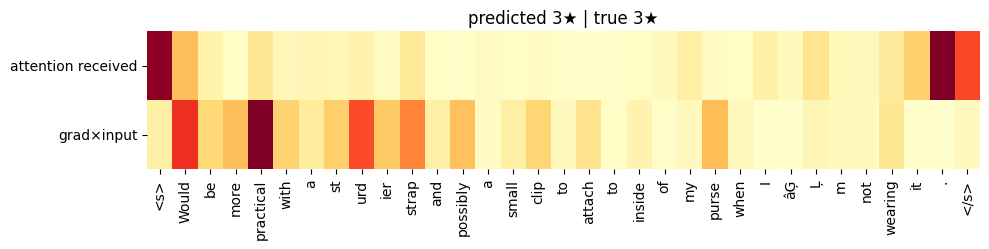

idx 1645: Purchased 4 for our family. We used 2 yesterday. The plastic is not durable. Within an hour, one of the cases got a small hole in the plastic and the other had some condensation inside. Luckily, we noticed before too much water got in and caused damage. We tested the products as suggested last week 


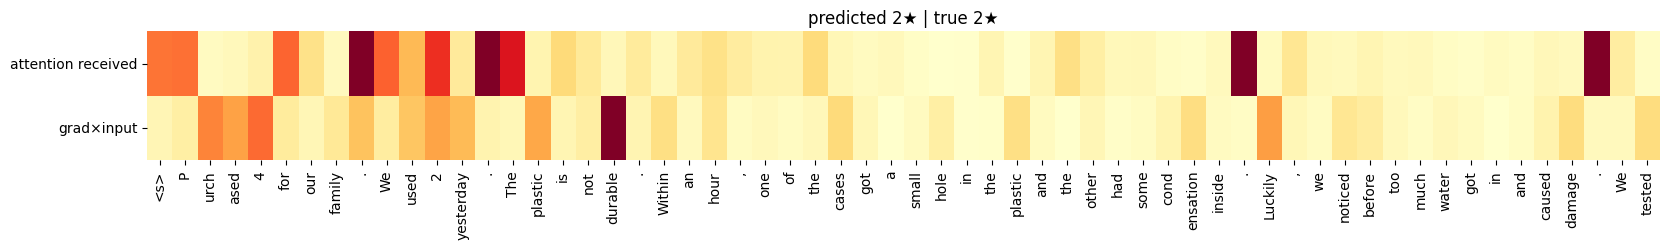

===== RoBERTa wrong, BiGRU correct =====
idx 1337: Stopped cooking the eggs properly after


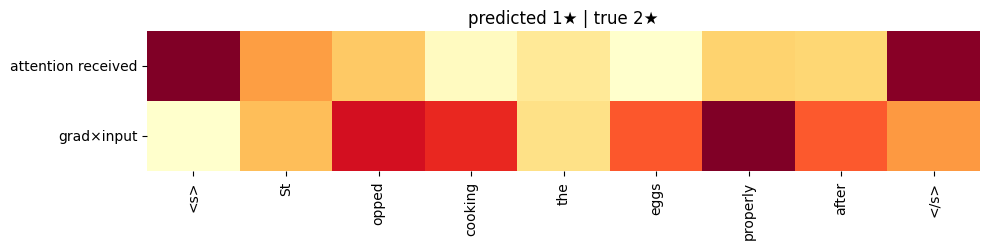

idx 2078: Good coffee but taste weak. The 24 hour brewing process is a bit of a pain. If you leave the bags in the water past the brewing time the coffee taste bitter. All that said, I will probably buy this product again, now that I know what to expect.


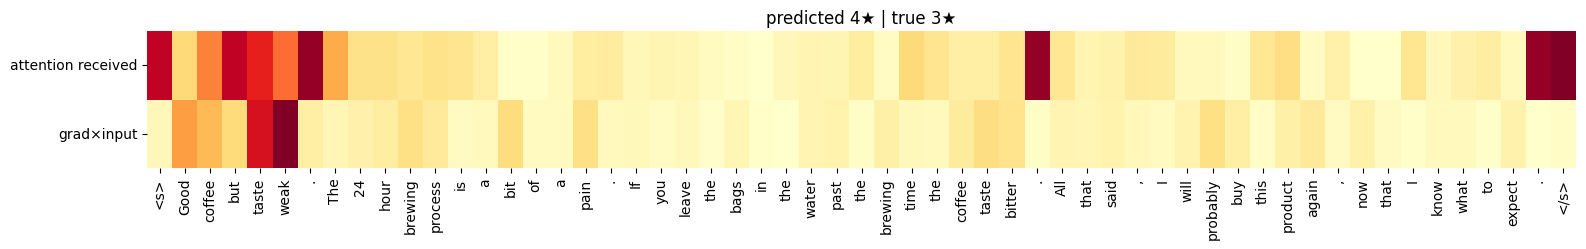

In [14]:
viz = RobertaCls(pooling='mean', attn_impl='eager').to(device)
viz.load_state_dict(torch.load(ckpt_path('mean', s0), map_location=device)); viz.eval()

def explain(text, true_label=None, tag='ex'):
    enc = tok_rb(text, truncation=True, max_length=MAX_LEN_RB, return_tensors='pt').to(device)
    ids, mask = enc['input_ids'], enc['attention_mask']
    toks = [t.replace('Ġ', '') for t in tok_rb.convert_ids_to_tokens(ids[0])]
    with torch.no_grad(): logits, atts = viz(ids, mask, output_attentions=True)
    pred = logits.argmax(1).item()
    att = atts[-1][0].mean(0).mean(0).cpu().numpy()                    # last layer, mean over heads and query positions
    emb = viz.enc.embeddings.word_embeddings(ids).detach().requires_grad_(True)
    with torch.enable_grad():
        lg = viz(None, mask, inputs_embeds=emb); lg[0, pred].backward()
    sal = (emb.grad * emb).norm(dim=-1)[0].detach().cpu().numpy()      # gradient x input saliency
    norm = lambda v: (v - v.min()) / (v.max() - v.min() + 1e-9)
    n = min(len(toks), 60)
    fig, a = plt.subplots(figsize=(max(10, n * 0.28), 2.6))
    sns.heatmap(np.vstack([norm(att[:n]), norm(sal[:n])]), xticklabels=toks[:n], yticklabels=['attention received', 'grad×input'], cmap='YlOrRd', cbar=False, ax=a)
    plt.xticks(rotation=90)
    a.set_title(f'predicted {pred+1}★' + (f' | true {true_label+1}★' if true_label is not None else ''))
    plt.tight_layout(); plt.savefig(f'{CKPT_DIR}/explain_{tag}.png', dpi=150, bbox_inches='tight'); plt.show()

print('===== RoBERTa correct, BiGRU wrong =====')
for i in rob_wins.sample(2, random_state=1).index:
    print(f'idx {i}:', q.text[i][:300]); explain(q.text[i], q.label[i], tag=f'correct_{i}')
print('===== RoBERTa wrong, BiGRU correct =====')
for i in base_wins.sample(2, random_state=1).index:
    print(f'idx {i}:', q.text[i][:300]); explain(q.text[i], q.label[i], tag=f'wrong_{i}')
del viz; torch.cuda.empty_cache()

### Observations on the token-importance heatmaps
Both rows are min-max normalised per review. Gradient × input is an unsigned magnitude, so it shows which tokens influenced the prediction, not in which direction.

- **Attention is mostly on structural tokens.** In all four reviews the strongest "attention received" is on `<s>`, `</s>` or full stops (and sentence-initial tokens in idx 1645), not on sentiment words. Raw last-layer attention is therefore a weak explanation here.
- **Gradient × input is more informative.** In idx 1645 (true 2★, predicted 2★) it peaks on *durable* in *"The plastic is not durable"*, the key complaint. In idx 2464 (true 3★, predicted 3★) it peaks on *practical* and *sturdier* in a suggestion-style sentence (*"Would be more practical with a sturdier strap…"*), consistent with a neutral verdict.
- **Attention and saliency mostly disagree.** The exception is idx 2078 (*"Good coffee but taste weak…"*), where attention also puts weight on *but*, *taste* and *weak*, in addition to the structural tokens.
- **The wrong predictions are adjacent-rating errors.** Idx 1337 (*"Stopped cooking the eggs properly after"*, true 2★, predicted 1★) is a truncated review; saliency is highest on *properly* and spread over *Stopped*, *cooking*, *eggs* and *after*, so the model reacts to the failure wording. Idx 2078 (true 3★, predicted 4★) is a mixed review; saliency peaks on *weak* and *taste*, but the positive closing sentence (*"I will probably buy this product again"*) has low saliency and attention, so the model does not seem to weigh the whole review.
- **Conclusion.** The heatmaps help see which tokens influenced a prediction, but attention weights alone should not be read as an explanation; gradient-based saliency is more plausible but remains indicative, and only four reviews were inspected.

## 10. Ablation: mean pooling vs first-token (`<s>`) pooling (RoBERTa)
Both variants use identical data, hyper-parameters, schedule and seed (42); only the pooling operator differs. They are compared on the **validation** set (best checkpoint of each run) so the test set stays untouched. The seed-to-seed difference of the mean-pooling model (seed 42 vs 43) is used as a yardstick for how large a gap has to be to mean anything.

In [15]:
rb_m = {s: best_row(HIST[('mean', s)]) for s in SEEDS}; rb_f = best_row(HIST[('first', 42)])
abl_df = pd.DataFrame([
    dict(pooling='mean (seed 42)', val_acc=rb_m[42].val_acc, val_macro_F1=rb_m[42].val_f1, val_loss=rb_m[42].val_loss),
    dict(pooling='mean (seed 43)', val_acc=rb_m[43].val_acc, val_macro_F1=rb_m[43].val_f1, val_loss=rb_m[43].val_loss),
    dict(pooling='first-token <s> (seed 42)', val_acc=rb_f.val_acc, val_macro_F1=rb_f.val_f1, val_loss=rb_f.val_loss)])
display(abl_df.round(4))
gap, noise = rb_m[42].val_f1 - rb_f.val_f1, abs(rb_m[42].val_f1 - rb_m[43].val_f1)
print(f'mean − first-token macro-F1 (seed 42): {gap:+.4f} | seed-to-seed difference of mean pooling: {noise:.4f}')
print('=> ' + ('the gap is within the seed-to-seed difference: no reliable evidence that either pooling is better.' if abs(gap) <= noise
               else f'{"mean" if gap > 0 else "first-token"} pooling is better by more than the seed-to-seed difference (still a single seed).'))

,pooling,val_acc,val_macro_F1,val_loss
0,mean (seed 42),0.6150,0.6116,0.9017
1,mean (seed 43),0.6084,0.6052,0.9065
2,first-token <s> (seed 42),0.6128,0.6096,0.9049


mean − first-token macro-F1 (seed 42): +0.0020 | seed-to-seed difference of mean pooling: 0.0064
=> the gap is within the seed-to-seed difference: no reliable evidence that either pooling is better.


### Interpretation of the ablation
Mean pooling reached validation macro-F1 0.6116 (seed 42) and 0.6052 (seed 43); first-token pooling reached 0.6096 (seed 42). The seed-42 gap of +0.0020 is smaller than the 0.0064 difference between the two mean-pooling seeds, and the ranking is the same for accuracy (0.6150 vs 0.6128) and validation loss (0.9017 vs 0.9049). Mean pooling is nominally better on all three metrics, but the difference is within seed noise, so we find no reliable evidence that the pooling choice matters here. The ablation used a single seed and the validation set.

## 11. Results summary (computed from the runs above)

In [16]:
def ms(n, c): return rows[n][c].mean(), rows[n][c].std()
print('Test set, mean ± std over seeds %s' % SEEDS)
for c in ['accuracy', 'macro_F1', 'MAE', 'adjacent_err', 'distant_err']:
    (b, bs), (r, rs) = ms(B, c), ms(R, c)
    per_seed = [rows[R][c][i] - rows[B][c][i] for i in range(len(SEEDS))]
    print(f'{c:13s} BiGRU {b:.4f} ± {bs:.4f} | RoBERTa {r:.4f} ± {rs:.4f} | RoBERTa − BiGRU {r-b:+.4f} (per seed: {", ".join(f"{x:+.4f}" for x in per_seed)})')
print()
for n in (B, R):
    print(f'{n}: adjacent errors = {ERR_SHARE[n][0]:.1%} of all errors, distant = {ERR_SHARE[n][1]:.1%}; lowest per-class F1: ' +
          ', '.join(f'{k+1}★ ({rows[n][f"F1_{k+1}star"].mean():.3f})' for k in np.argsort([rows[n][f'F1_{k+1}star'].mean() for k in range(5)])[:2]))
print(f'\nParameters: BiGRU {P_BASE:.2f}M | RoBERTa {P_RB:.1f}M (x{P_RB/P_BASE:.1f})')
print(f'Time per run: BiGRU {np.mean([MINS[("baseline", s)] for s in SEEDS]):.1f} min | RoBERTa {np.mean([MINS[("mean", s)] for s in SEEDS]):.1f} min')
print(f'BiGRU best epoch: ' + ', '.join(f'seed {s}: {best_row(HIST[("baseline", s)]).epoch:.0f} of {len(HIST[("baseline", s)])}' for s in SEEDS))
print(f'RoBERTa best eval point: ' + ', '.join(f'seed {s}: epoch {best_row(HIST[("mean", s)]).epoch} of {HIST[("mean", s)].epoch.max()}' for s in SEEDS))
print(f'Ablation gap (mean − first-token, val macro-F1): {gap:+.4f} vs seed-to-seed difference {noise:.4f}')

Test set, mean ± std over seeds [42, 43]
accuracy      BiGRU 0.5754 ± 0.0059 | RoBERTa 0.6139 ± 0.0041 | RoBERTa − BiGRU +0.0385 (per seed: +0.0456, +0.0314)
macro_F1      BiGRU 0.5712 ± 0.0048 | RoBERTa 0.6112 ± 0.0042 | RoBERTa − BiGRU +0.0400 (per seed: +0.0464, +0.0337)
MAE           BiGRU 0.5129 ± 0.0052 | RoBERTa 0.4385 ± 0.0038 | RoBERTa − BiGRU -0.0744 (per seed: -0.0808, -0.0680)
adjacent_err  BiGRU 0.3554 ± 0.0076 | RoBERTa 0.3412 ± 0.0040 | RoBERTa − BiGRU -0.0142 (per seed: -0.0224, -0.0060)
distant_err   BiGRU 0.0692 ± 0.0017 | RoBERTa 0.0449 ± 0.0001 | RoBERTa − BiGRU -0.0243 (per seed: -0.0232, -0.0254)

BiGRU+Attn: adjacent errors = 83.7% of all errors, distant = 16.3%; lowest per-class F1: 3★ (0.422), 2★ (0.474)
RoBERTa (mean): adjacent errors = 88.4% of all errors, distant = 11.6%; lowest per-class F1: 3★ (0.491), 2★ (0.513)

Parameters: BiGRU 8.03M | RoBERTa 124.1M (x15.4)
Time per run: BiGRU 9.7 min | RoBERTa 54.3 min
BiGRU best epoch: seed 42: 4 of 7, seed 43: 3 of

### Final comparative analysis
1. **RoBERTa is better on every metric.** On the test set it gains +3.9 points accuracy (0.6139 vs 0.5754), +4.0 points macro-F1 (0.6112 vs 0.5712) and lowers MAE by 0.074 stars (0.4385 vs 0.5129, −14.5%). The gain is consistent across seeds (+4.6 and +3.1 points accuracy) and larger than the seed standard deviations (≤0.006).
2. **It respects the ordinal structure better.** Distant errors (2+ stars) fall from 6.9% to 4.5% of all reviews (−35%). Adjacent errors fall less (35.5% → 34.1%), so they make up 83.7% of the BiGRU's errors and 88.4% of RoBERTa's. 1★↔5★ confusions are rare for both (≤1.4% of a class).
3. **Adjacent confusion is not removed.** 4★→5★ confusion is not lower for RoBERTa (0.242 vs 0.234), and 4★ recall is no better (0.53 vs 0.55). The largest gains are on 3★ (recall 0.39 → 0.48, F1 +0.069) and 5★ (recall 0.76 → 0.81); 3★ and 2★ remain the hardest classes for both models.
4. **Training behaviour.** The BiGRU overfits quickly: validation loss is lowest around epochs 2–3 and then rises to about 1.2 (seed 42) while training loss falls to about 0.65, so early stopping chose epoch 4 (seed 42) and epoch 3 (seed 43). RoBERTa shows a smaller train/validation gap (training macro-F1 about 0.63 vs validation 0.605–0.612). Its best checkpoint was the last evaluation in both seeds, so it may not be fully converged.
5. **Cost.** RoBERTa has 15.4× the parameters (124.1M vs 8.03M) and needs about 5.6× the training time per run (54.3 vs 9.7 min).
6. **Explainability.** Raw attention weights highlighted mostly special tokens and punctuation, while gradient × input pointed to plausible sentiment words, so attention alone is not a reliable explanation.
7. **Limitations.** Only 2 seeds (the standard deviation from two values is a rough estimate); one-seed ablation on validation data; RoBERTa trained for only 2 epochs with no hyper-parameter tuning; the BiGRU is regularised by early stopping while RoBERTa uses a fixed budget; reviews truncated at 200/256 tokens; the test set has 5,000 reviews, so differences below about 1 point should not be over-interpreted; qualitative conclusions come from a small number of examples and rule-based tags.
8. **Reproducibility note.** The five runs (two BiGRU runs in notebook 2, three RoBERTa runs in this notebook) were completed over two sessions with the same code and the same Drive folder; their training logs are printed in the training-log sections of notebooks 2 and 3. Each run's history was saved, and the verification sections of notebooks 2 and 3 re-scored every checkpoint on the validation set and matched the logged value.